# The Midas Touch: Hype vs Reality 👑✨

**Data Storytelling by Andres Felipe Rosero Lopez**

---

### 🎯 The Conflict: Hype (Expectation) vs Reality (Score)

Every great story needs a conflict. In the world of anime, this conflict is often between **Hype** (how many people follow a work) and **Reality** (the actual perceived quality, the score).

In this notebook, we will explore:
1.  **Hype vs Reality**: Does a big name attract people, but only quality keeps them?
2.  **The Midas Touch**: Are great directors (Miyazaki, Shinkai, Yuasa) truly infallible?
3.  **One Hit Wonders**: The curse of the masterpiece. What happens if we remove the main work from authors?
4.  **The Sounds of Success**: The impact of composers (e.g., Hiroyuki Sawano) on the score.
5.  **Star Value (VORD)**: A "sabermetric" comparison between directors and studios.
6.  **Studio DNA**: Does every studio have a quality fingerprint?
7.  **Originals vs Adaptations**: Is an original anime a risk worth taking?

**Goal**: To demonstrate that *"Fame opens the door, but consistency builds the temple."*

### 💡 Insight: Boutique vs. Factory

Every studio has a business model, and it's visible in the dots. 
- **The Boutique (e.g., Kyoto Animation)**: notice the tight clustering at the top. They prioritize "Quality Control" above all, releasing fewer shows but polishing them to a mirror finish.
- **The Factory**: Other studios show a massive spread from 4.0 to 9.0. Their strategy is "Shotgun Approach"—produce everything, accepting that for every hit, there will be several forgettable fillers.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import sys
import warnings

# Add parent directory to path to import src
sys.path.append('..')
from src.data import load_processed

# Settings
pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Custom Color Palette
hype_color = '#FFD700' # Gold for Midas
reality_color = '#2E8B57' # Green for Reality

print("Environment configured. ✅")

Environment configured. ✅


## 1. Data Loading & Cleaning 🧹

We load the main datasets and those related to staff/people.
The main challenge here is **name normalization**, since we often find different formats (Family Name Given Name vs Given Name Family Name).

In [16]:
print("Loading core datasets...")
try:
    df_details = load_processed("details")
    df_stats = load_processed("stats")
    
    # Merge Core
    df = df_details.merge(df_stats, on="anime_id", how="inner")
    print(f"Main dataset loaded: {df.shape[0]} anime.")
    
except Exception as e:
    print(f"Error loading core data: {e}")

print("Loading people & staff datasets...")
try:
    # Loading Staff/Person data
    # We need to link anime -> staff -> person details
    df_person_details = load_processed("person_details")
    df_person_works = load_processed("person_anime_works")
    
    print(f"Person Details: {df_person_details.shape[0]} people.")
    print(f"Person Works: {df_person_works.shape[0]} records.")
    
except Exception as e:
    print(f"Error loading people data: {e}")

Loading core datasets...
Main dataset loaded: 28939 anime.
Loading people & staff datasets...
Person Details: 76696 people.
Person Works: 458091 records.


In [17]:
# Normalize Names Function
def normalize_name(name):
    """
    Normalizes names to 'Given Name Family Name' format.
    Handles 'Family, Given' format by swapping.
    """
    if pd.isna(name):
        return "Unknown"
    
    name = str(name).strip()
    
    if ',' in name:
        parts = name.split(',')
        if len(parts) >= 2:
            # Assuming "Family, Given" -> return "Given Family"
            return f"{parts[1].strip()} {parts[0].strip()}"
            
    return name

# Apply Normalization
if 'name' in df_person_details.columns:
    df_person_details['normalized_name'] = df_person_details['name'].apply(normalize_name)
    print("Name normalization applied.")
else:
    print("Column 'name' not found in person_details. Please check columns:", df_person_details.columns)

Name normalization applied.


## Chapter 2: The Hype Factor 💥

**The Hypothesis**: "A big name attracts people (Members), but only quality keeps them (Score)."

We analyze the **Members/Score** ratio.
- A high number of members with a mediocre score indicates **Disappointed Hype**.
- We look for titles where expectations were sky-high but the result was... questionable.

In [41]:
# Filter for relevant anime (exclude extremely niche ones to avoid noise)
df_analysis = df[df['members'] > 10000].copy()

# Calculate Hype Ratio (Members per Score point)
df_analysis['hype_ratio'] = df_analysis['members'] / df_analysis['score']

# Identify High Hype, Low Score (The Flops)
top_hype_flops = df_analysis.sort_values(by='hype_ratio', ascending=False).head(20)

fig = px.scatter(df_analysis, x='score', y='members', 
                 hover_name='title', 
                 title='The Hype Landscape: Members vs Score',
                 color='score',
                 color_continuous_scale='RdYlGn',
                 log_y=True)

# Highlight the "Flops"
fig.add_trace(go.Scatter(x=top_hype_flops['score'], y=top_hype_flops['members'],
                         mode='markers',
                         marker=dict(color='red', size=10, symbol='x'),
                         name='High Hype/Low Score'))

# Move the legend to the top-left to avoid overlapping
fig.update_layout(
    legend=dict(
        orientation="h",   # Horizontal legend
        yanchor="bottom",
        y=1.02,             # Positioned above the plot
        xanchor="left",
        x=0                 # Aligned to the left
    ),
    template='plotly_white'
)

fig.show()

### 💡 Insight: Is Popularity a Trap?

Data tells us a distinct story about **Hype vs. Quality**. While it's true that masterpieces often attract crowds (top-right corner), the "Danger Zone" in the bottom-right (High Members, Low Score) serves as a warning.

This cluster represents the **"Marketing Triumph / Content Failure"** phenomenon. These shows had the budget to get your attention but lacked the substance to keep your respect. In contrast, the sparse top-left corner reminds us that true hidden gems are rare—in the internet age, quality usually finds its audience eventually.

## Chapter 3: The Seal of Quality (Ridgeline Plots) 🏔️

We analyze the consistency of great directors.
We use a **Ridgeline Plot** to visualize the distribution of scores for selected directors (e.g., Miyazaki, Shinkai, Yuasa, Araki).

- **Narrow and high mountain on the right**: Consistent and high-quality author.
- **Wide mountain**: Unpredictable author.

### 💡 Insight: The "Seal of Quality"

When you see a name like **Hayao Miyazaki** or **Makoto Shinkai** on a poster, you're not just buying a ticket; you're buying a guarantee. The graph shows their score distributions are not just high, but **compact**.

This "thin and high" shape is the visual definition of **consistency**. Unlike directors who oscillate between hits and misses (represented by wider, stretched shapes), these masters rarely drop the ball. Their "worst" days are often better than others' best days, making them the safest bets in the industry.

In [46]:
# Prepare Data for Directors
director_works = df_person_works[df_person_works['position'].str.contains('Director', case=False, na=False)]
director_works = director_works.merge(df_person_details[['person_id', 'normalized_name']], 
                                      left_on='person_id', right_on='person_id', how='left')
director_scores = director_works.merge(df[['anime_id', 'title', 'score', 'studios']], on='anime_id', how='inner')

target_directors = ['Hayao Miyazaki', 'Makoto Shinkai', 'Masaaki Yuasa', 'Hideaki Anno', 'Mamoru Hosoda', 'Naoko Yamada', 'Shinichirou Watanabe']
available_directors = [d for d in target_directors if d in director_scores['normalized_name'].unique()]
plot_data = director_scores[director_scores['normalized_name'].isin(available_directors)]

if len(plot_data) > 0:
    fig = go.Figure()
    # Sort available directors for consistent visual order
    available_directors_sorted = plot_data.groupby('normalized_name')['score'].median().sort_values(ascending=False).index
    
    for director in available_directors_sorted:
        director_data = plot_data[plot_data['normalized_name'] == director]['score']
        # Removed y0=0 to allow names to appearing on the Y-axis
        fig.add_trace(go.Violin(x=director_data, 
                                name=director, 
                                side='positive',
                                orientation='h',
                                width=1.5,
                                points='all'))

    fig.update_layout(title='Director Consistency: Score Distributions',
                      xaxis_title='Score',
                      yaxis_title='Director',
                      showlegend=False,
                      height=700,
                      template='plotly_white')
    fig.show()
else:
    print("No data found for selected directors.")

### 💡 Insight: The "Seal of Quality"

When you see a name like **Hayao Miyazaki** or **Makoto Shinkai** on a poster, you're not just buying a ticket; you're buying a guarantee. The graph shows their score distributions are not just high, but **compact**.

This "thin and high" shape is the visual definition of **consistency**. Unlike directors who oscillate between hits and misses (represented by wider, stretched shapes), these masters rarely drop the ball. Their "worst" days are often better than others' best days, making them the safest bets in the industry.

## Chapter 4: The Curse of the Masterpiece (One Hit Wonder) 🥀

If we remove the main work (the masterpiece), what remains of the author's prestige?
We calculate the "Prestige Drop".

In [7]:
# Re-use director_scores

prestige_analysis = []

for director in top_directors_list:
    d_data = director_scores[director_scores['normalized_name'] == director]
    if d_data.empty: continue
        
    avg_score_all = d_data['score'].mean()
    max_score = d_data['score'].max()
    
    # Remove the masterpiece (highest score)
    # Handle ties by removing only one instance or all? Let's remove the max value instances.
    d_data_no_masterpiece = d_data[d_data['score'] < max_score]
    
    if d_data_no_masterpiece.empty:
        avg_score_no_masterpiece = 0 # Or NaN
    else:
        avg_score_no_masterpiece = d_data_no_masterpiece['score'].mean()
        
    prestige_drop = avg_score_all - avg_score_no_masterpiece
    
    prestige_analysis.append({
        'Director': director,
        'Works Count': len(d_data),
        'Avg Score (All)': avg_score_all,
        'Avg Score (w/o Masterpiece)': avg_score_no_masterpiece,
        'Prestige Drop': prestige_drop,
        'Masterpiece Score': max_score
    })

df_prestige = pd.DataFrame(prestige_analysis)

# Filter directors with significant drops (Positive Prestige Drop means average goes DOWN without masterpiece)
# We look for the largest drops
one_hit_wonders = df_prestige[df_prestige['Works Count'] >= 3].sort_values(by='Prestige Drop', ascending=False).head(15)

fig = px.bar(one_hit_wonders, x='Director', y='Prestige Drop',
             title='The Curse of the Masterpiece: Drop in Average Score when removing the best work',
             color='Prestige Drop', color_continuous_scale='OrRd',
             hover_data=['Avg Score (All)', 'Avg Score (w/o Masterpiece)', 'Masterpiece Score'])
fig.show()

### 💡 Insight: The Curse of the Masterpiece

Creating a masterpiece is a blessing and a curse. This chart tracks the "Prestige Drop"—what happens when we take away a director's most famous work?

For true auteurs, the bar barely moves. Their career is built on a catalogue of excellence. But for others, the bar collapses. These are the **"One Hit Wonders"**—creators who caught lightning in a bottle once but struggled to replicate that magic. It highlights the difference between a lucky strike and sustained genius.

## Extension: Sounds of Success (Composers) 🎵

Does Hiroyuki Sawano (and other top composers) really raise the average?
Let's compare the score of anime with these composers vs the global average.

In [8]:
# Filter works for Music/Composer role
# Roles often include "Music", "Theme Song Performance", etc.
composer_works = df_person_works[df_person_works['position'].str.contains('Music', case=False, na=False)]

# Merge with Person Names
composer_works = composer_works.merge(df_person_details[['person_id', 'normalized_name']], 
                                      left_on='person_id', right_on='person_id', how='left')

# Merge with Anime Scores
composer_scores = composer_works.merge(df[['anime_id', 'title', 'score']], on='anime_id', how='inner')

target_composers = ['Hiroyuki Sawano', 'Yuki Kajiura', 'Yoko Kanno', 'Joe Hisaishi', 'Kensuke Ushio']

composer_comparison = []
global_avg = df['score'].mean()

for composer in target_composers:
    c_data = composer_scores[composer_scores['normalized_name'] == composer]
    if c_data.empty: continue
    
    avg_score = c_data['score'].mean()
    uplift = avg_score - global_avg
    
    composer_comparison.append({
        'Composer': composer,
        'Works Count': len(c_data),
        'Avg Score': avg_score,
        'Global Avg': global_avg,
        'Score Uplift': uplift
    })

df_composers = pd.DataFrame(composer_comparison)

fig = go.Figure()
fig.add_trace(go.Bar(x=df_composers['Composer'], y=df_composers['Score Uplift'], 
                     marker_color='teal', name='Score Uplift vs Average'))

fig.update_layout(title='The Composer Effect: Score Uplift vs Global Average',
                  yaxis_title='Score Points above Average')
fig.show()

## Special Chapter: Studio DNA 🧬

Do animation studios have a quality "fingerprint"? Let's analyze the consistency of the Big Names.
Is KyoAni really synonymous with constant excellence?

### 💡 Insight: Boutique vs. Factory

Every studio has a business model, and it's visible in the dots. 
- **The Boutique (e.g., Kyoto Animation)**: notice the tight clustering at the top. They prioritize "Quality Control" above all, releasing fewer shows but polishing them to a mirror finish.
- **The Factory**: Other studios show a massive spread from 4.0 to 9.0. Their strategy is "Shotgun Approach"—produce everything, accepting that for every hit, there will be several forgettable fillers.

In [9]:
# Filter Top Studios
target_studios = ['Kyoto Animation', 'Madhouse', 'MAPPA', 'Bones', 'Sunrise', 'A-1 Pictures', 'J.C.Staff', 'Studio Ghibli', 'ufotable', 'Production I.G']

studio_scores = []
for studio in target_studios:
    s_data = df[df['studios'].astype(str).str.contains(studio, na=False)]
    if len(s_data) > 0:
        temp_df = s_data[['title', 'score']].copy()
        temp_df['Studio'] = studio
        studio_scores.append(temp_df)

df_studio_dna = pd.concat(studio_scores)
studio_order = df_studio_dna.groupby('Studio')['score'].median().sort_values(ascending=False).index

fig = go.Figure()
for studio in studio_order:
    data = df_studio_dna[df_studio_dna['Studio'] == studio]['score']
    # Removed y0=0 to allow Plotly to stack them on the Y-axis correctly
    fig.add_trace(go.Violin(x=data, name=studio, orientation='h', side='positive', width=1.3, points=False))

fig.update_layout(title='Studio DNA: Score Consistency & Quality',
                  xaxis_title='Score', 
                  yaxis_title='Studio',
                  showlegend=False,
                  height=800,
                  template='plotly_white')
fig.show()

### 💡 Insight: The "Seal of Quality"

When you see a name like **Hayao Miyazaki** or **Makoto Shinkai** on a poster, you're not just buying a ticket; you're buying a guarantee. The graph shows their score distributions are not just high, but **compact**.

This "thin and high" shape is the visual definition of **consistency**. Unlike directors who oscillate between hits and misses (represented by wider, stretched shapes), these masters rarely drop the ball. Their "worst" days are often better than others' best days, making them the safest bets in the industry.

## Extra Chapter: VORD (Value Over Replacement Director) ⚾

Inspired by Sabermetrics ("Moneyball"): how much value does a director add compared to the "average" of their studio?
If Hayao Miyazaki directs a Ghibli film, how much score does it gain compared to a Ghibli film *not* directed by him?

**Formula**: `VORD = (Avg Score Director at Studio X) - (Avg Score Studio X without Director)`

In [10]:
# Calculate VORD for selected Directors
# Logic:
# 1. Iterate through directors.
# 2. Find their main studio (most frequent).
# 3. Calculate Avg Score of Director @ Studio.
# 4. Calculate Avg Score of Studio (excluding Director).
# 5. Difference is VORD.

vord_data = []

for director in target_directors:
    # Get director works
    d_works = director_scores[director_scores['normalized_name'] == director]
    if d_works.empty: continue
    
    # Get main studio (most frequent)
    # Studios col is comma separated string. Let's simplistically take the first one listed for grouping or explode.
    # For better accuracy, we look at the studio string.
    main_studio = d_works['studios'].mode()[0]
    if pd.isna(main_studio): continue
        
    # Clean studio name (first element if multiple)
    main_studio_clean = main_studio.split(',')[0].strip()
    
    # Get all works from that studio
    all_studio_works = df[df['studios'].str.contains(main_studio_clean, na=False)]
    
    # Exclude director's works
    studio_works_no_director = all_studio_works[~all_studio_works['anime_id'].isin(d_works['anime_id'])]
    
    if studio_works_no_director.empty: 
        # The director IS the studio (e.g. maybe Shinkai early Comix Wave?)
        continue
        
    score_director = d_works[d_works['studios'].str.contains(main_studio_clean, na=False)]['score'].mean()
    score_replacement = studio_works_no_director['score'].mean()
    
    vord = score_director - score_replacement
    
    vord_data.append({
        'Director': director,
        'Main Studio': main_studio_clean,
        'Director Avg': score_director,
        'Studio Baseline': score_replacement,
        'VORD': vord
    })

df_vord = pd.DataFrame(vord_data).sort_values(by='VORD', ascending=False)

fig = px.bar(df_vord, x='Director', y='VORD',
             title='VORD: Value Over Replacement Director (Score Impact vs Studio Average)',
             hover_data=['Main Studio', 'Director Avg', 'Studio Baseline'],
             color='VORD', color_continuous_scale='Viridis')
fig.show()

### 💡 Insight: The "Messi" Statistic (VORD)

In sports, we measure a player's value by how much better the team performs with him on the field. **Value Over Replacement Director (VORD)** applies this logic to Anime.

A positive VORD means the director is a **Force Multiplier**: they take a studio's resources and produce something significantly better than the studio's average output. A score of +1.0 literally means *"This person adds a full star to the rating just by showing up."*

## Risk Chapter: Original vs Adaptation 🎲

Is creating an original anime a bigger gamble than adapting a popular manga?
We compare the **Standard Deviation** and the **Distribution** of scores by Source.

In [11]:
# Setup Source Group Mapping if not present (simulating run)
def map_source_group(source):
    if pd.isna(source): return "Unknown"
    source = str(source).strip()
    if source in ['Manga', '4-koma manga', 'Web manga', 'Digital manga']: return 'Manga First'
    elif source in ['Light novel', 'Novel', 'Visual novel', 'Book']: return 'Novel First'
    elif source == 'Original': return 'Original'
    elif source in ['Game', 'Card game']: return 'Game'
    else: return 'Other'

df['source_group'] = df['source'].apply(map_source_group)

# Filter main groups
main_sources = ['Manga First', 'Novel First', 'Original', 'Game']
df_risk = df[df['source_group'].isin(main_sources)]

# Box Plot to show variance (Risk)
fig = px.box(df_risk, x='source_group', y='score', 
             color='source_group',
             title='The Risk Profile: Score Distribution by Source Material',
             points='outliers') # outliers only to reduce rendering load

fig.update_layout(xaxis_title='Source Material',
                  yaxis_title='Score')
fig.show()

# Calculate Stats
risk_stats = df_risk.groupby('source_group')['score'].agg(['mean', 'std', 'count']).sort_values(by='std', ascending=False)
print("Risk Analysis Stats (Standard Deviation = Volatility):")
print(risk_stats)

Risk Analysis Stats (Standard Deviation = Volatility):
                  mean       std  count
source_group                           
Original      6.066450  0.878572   6288
Manga First   6.797031  0.837418   5740
Novel First   6.626904  0.792264   2988
Game          6.331161  0.710042   1291


### 💡 Insight: The Risk/Reward Trade-off

This is the investor's guide to Anime. 
- **Originals are 'Startups'**: They have the highest variance. Without an existing fanbase or manga to lean on, they assume massive creative risk. They either crash hard or define a generation (high volatility).
- **Adaptations are 'Blue Chips'**: Manga and Light Novel adaptations are safer. The story is pre-tested. They rarely flop disastrously, but they are also constrained by their source material, making it harder to surprise the audience.

## Chapter 8: The Prejudice Threshold (Pre-Release vs Final Score) 🚀

Is the public more lenient with "Big Names" at the beginning?
We compare the average score of **currently airing** anime (early impressions) vs **finished** anime for top studios/directors.
Hypothesis: Big Studios start with a "Trust Bonus" (e.g. +0.5 score) which might normalize later.

In [12]:
# Analysis of Prejudice Threshold - Slope Chart
import plotly.graph_objects as go

# Filter for Big Studios
target_studios_extended = ['Kyoto Animation', 'Madhouse', 'MAPPA', 'Bones', 'Sunrise', 
                           'A-1 Pictures', 'J.C.Staff', 'Studio Ghibli', 'ufotable', 
                           'Production I.G', 'CloverWorks', 'Wit Studio']

prejudice_data = []

print("Analyzing Prejudice Threshold for Studios:")
for studio in target_studios_extended:
    s_works = df[df['studios'].astype(str).str.contains(studio, na=False)]
    airing = s_works[s_works['status'] == 'Currently Airing']
    finished = s_works[s_works['status'] == 'Finished Airing']
    
    if len(airing) > 0 and len(finished) > 0:
        avg_airing = airing['score'].mean()
        avg_finished = finished['score'].mean()
        prejudice_data.append({'Studio': studio, 'Status': 'Airing (Early)', 'Score': avg_airing})
        prejudice_data.append({'Studio': studio, 'Status': 'Finished (Final)', 'Score': avg_finished})

df_slope = pd.DataFrame(prejudice_data)

if not df_slope.empty:
    fig = go.Figure()
    studios_list = df_slope['Studio'].unique()
    
    for studio in studios_list:
        d = df_slope[df_slope['Studio'] == studio]
        # Slope line
        fig.add_trace(go.Scatter(x=d['Status'], y=d['Score'], mode='lines+markers', name=studio,
                                 line=dict(width=2), marker=dict(size=8)))
    
    fig.update_layout(
        title='The Prejudice Threshold: Airing vs Finished Score Trajectory',
        yaxis_title='Average Score',
        xaxis_title='Status',
        xaxis=dict(type='category'),
        showlegend=True
    )
    fig.show()
else:
    print("Not enough data for Slope Chart.")

Analyzing Prejudice Threshold for Studios:


### 💡 Insight: The "Trust Bonus" vs. Reality Check

Does hype survive the airing schedule? 
- **Downward Slopes**: These reveal the "broken promises." We tuned in expecting greatness (high early score), but the show lost steam. The initial trust was misplaced.
- **Flat Lines**: This is the mark of reliability. The studio delivered exactly what the audience expected.
- **Upward Slopes**: The rarest breed—the "Sleeper Hits." Shows that started quietly but proved themselves episode by episode, winning over the skeptics.

## Chapter 9: Longevity of Success (Trend over Time) ⏳

How does the popularity of an author's work grow over the years?
We visualize the **Cumulative Members** count for top directors, animated by year of release.
Do Miyazaki's classics accumulate fans faster than modern hits? Does a director's career accelerate over time?

In [13]:
# Analysis of Longevity (Cumulative Members) - Animated with Slider
import plotly.graph_objects as go
import pandas as pd
import numpy as np

target_directors = ['Hayao Miyazaki', 'Makoto Shinkai', 'Masaaki Yuasa', 'Hideaki Anno', 'Mamoru Hosoda', 'Naoko Yamada', 'Shinichirou Watanabe']

def local_normalize(name):
    if pd.isna(name): return 'Unknown'
    name = str(name).strip()
    if ',' in name:
        parts = name.split(',')
        if len(parts) >= 2: return f'{parts[1].strip()} {parts[0].strip()}'
    return name

df_p_details = df_person_details.copy()
df_p_details['norm_name'] = df_p_details['name'].apply(local_normalize)
director_works = df_person_works[df_person_works['position'].str.contains('Director', case=False, na=False)]
director_full = director_works.merge(df_p_details[['person_id', 'norm_name']], on='person_id')
director_target = director_full[director_full['norm_name'].isin(target_directors)]
director_anime = director_target.merge(df[['anime_id', 'title', 'members', 'start_date']], on='anime_id')
director_anime['year'] = pd.to_datetime(director_anime['start_date'], errors='coerce').dt.year
director_anime = director_anime.dropna(subset=['year'])
director_anime['year'] = director_anime['year'].astype(int)

yearly_stats = director_anime.groupby(['norm_name', 'year'])['members'].sum().reset_index()
yearly_stats.columns = ['Director', 'Year', 'Yearly_Members']
all_years = sorted(director_anime['year'].unique())
grid = pd.MultiIndex.from_product([target_directors, all_years], names=['Director', 'Year']).to_frame(index=False)
df_longevity = grid.merge(yearly_stats, on=['Director', 'Year'], how='left').fillna(0)
df_longevity = df_longevity.sort_values(['Director', 'Year'])
df_longevity['Cumulative Members'] = df_longevity.groupby('Director')['Yearly_Members'].cumsum()

max_y = df_longevity['Cumulative Members'].max() * 1.1
first_year = min(all_years)

frames = []
for y in all_years:
    frame_traces = []
    for director in target_directors:
        d_data = df_longevity[(df_longevity['Director'] == director) & (df_longevity['Year'] <= y)]
        frame_traces.append(go.Scatter(x=d_data['Year'], y=d_data['Cumulative Members']))
    frames.append(go.Frame(data=frame_traces, name=str(y)))

slider_steps = []
for y in all_years:
    slider_steps.append(dict(
        method='animate', label=str(y),
        args=[[str(y)], {'frame': {'duration': 300, 'redraw': False}, 'mode': 'immediate', 'transition': {'duration': 300}}]
    ))

fig = go.Figure(
    data=[go.Scatter(x=df_longevity[(df_longevity['Director'] == d) & (df_longevity['Year'] <= first_year)]['Year'],
                     y=df_longevity[(df_longevity['Director'] == d) & (df_longevity['Year'] <= first_year)]['Cumulative Members'],
                     name=d, mode='lines+markers') for d in target_directors],
    layout=go.Layout(
        title='Longevity of Success: Cumulative Audience Growth over Career',
        xaxis=dict(range=[min(all_years), max(all_years)], title='Year', autorange=False),
        yaxis=dict(range=[0, max_y], title='Cumulative Members', autorange=False),
        updatemenus=[dict(
            type='buttons', direction='left', pad={'r': 10, 't': 87}, showactive=False, x=0.1, xanchor='right', y=0, yanchor='top',
            buttons=[dict(label='Play', method='animate', args=[None, {'frame': {'duration': 90, 'redraw': False}, 'fromcurrent': True}]),
                     dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate', 'transition': {'duration': 0}}])]
        )],
        sliders=[dict(active=0, currentvalue={'prefix': 'Year: '}, pad={'t': 50}, steps=slider_steps, x=0.1, len=0.9, xanchor='left', y=0, yanchor='top')]
    ), frames=frames
)
fig.show()


### 💡 Insight: Building an Empire

Watch the lines race. This isn't just about how many fans a director has—it's about **acceleration**.

A steep, vertical climb indicates a "Golden Age" where every release was a blockbuster event. But pay attention to the old masters: their lines continue to rise steadily even decades after release. This is the definition of **Timelessness**—their work is not just consumed; it is discovered by new generations, year after year.

## Chapter 10: The Geography of Fame (Global Impact) 🌍

Art knows no borders, but does it have a 'home' level of popularity? By analyzing where fans of different directors live, we can see their global cultural footprint.

We use a **Choropleth Map** to visualize the global popularity of a chosen director's works. For instance, is Makoto Shinkai's modern aesthetic more concentrated in Asia compared to Hayao Miyazaki's universal appeal?

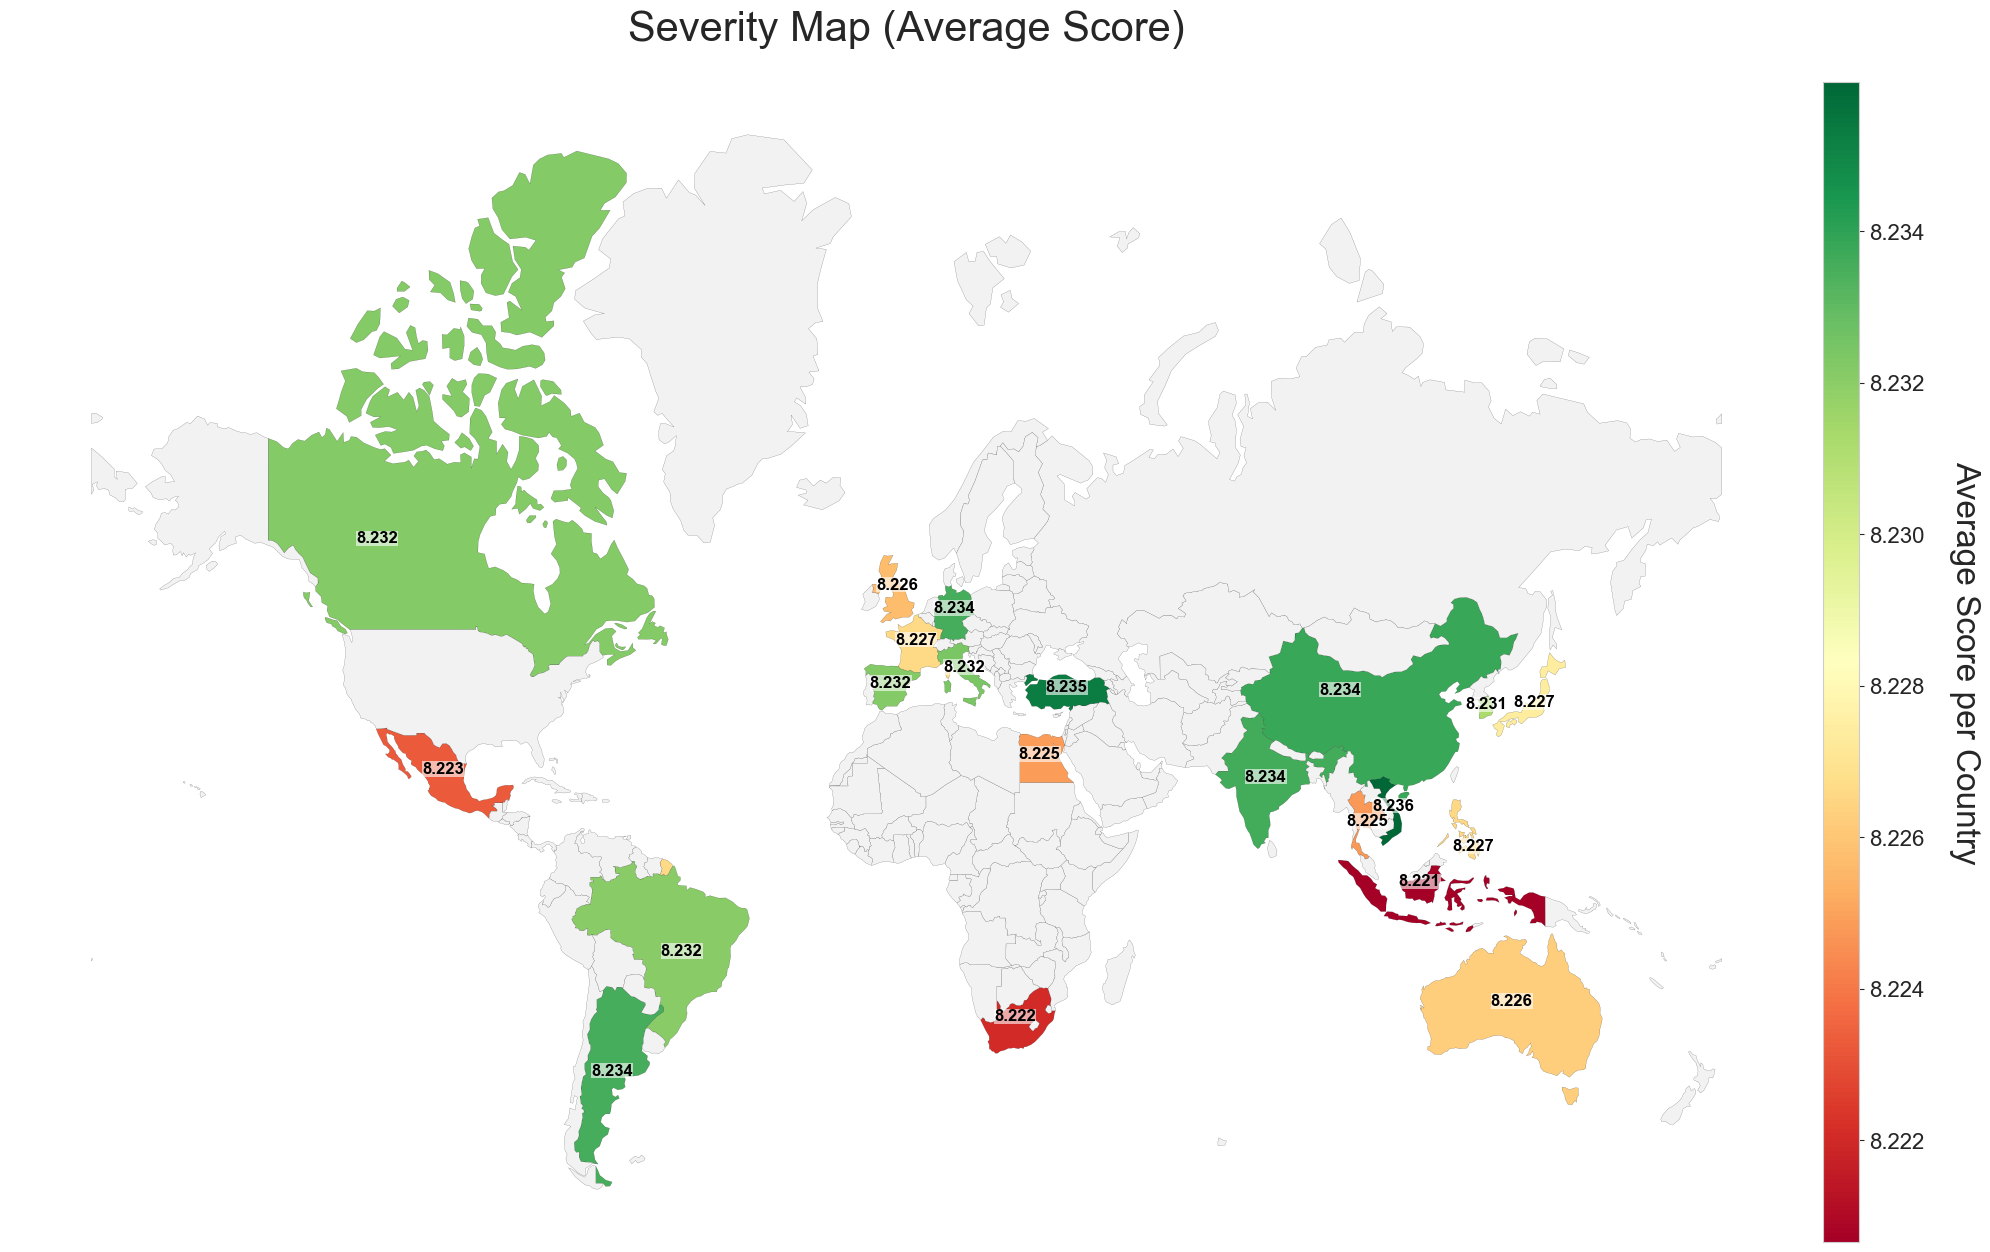

In [14]:
# Analysis: Geography of Fame (Severity Map)
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import pandas as pd
import numpy as np

try:
    # 1. Data Loading
    profiles = pd.read_parquet('../../data/processed/profiles.parquet')[['username', 'location']]
    favs = pd.read_parquet('../../data/processed/favs.parquet')
    favs_anime = favs[favs['fav_type'] == 'anime']
    
    # Linked with 'df' which is the main dataframe already loaded in the notebook (stats+details)
    df_scores = favs_anime.merge(df[['anime_id', 'score']], left_on='id', right_on='anime_id')
    df_geo = df_scores.merge(profiles, on='username')
    
    # Metrics Calculation
    analysis = df_geo.groupby('location')['score'].mean().reset_index()
    analysis.columns = ['country', 'avg_score']

    # 2. Map Loading (Using direct URL for GeoPandas 1.0+ compatibility without geodatasets)
    world = gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip")
    
    # Merge and cleaning
    world_data = world.merge(analysis, left_on='NAME', right_on='country', how='left')
    world_data = world_data[world_data['NAME'] != 'Antarctica'].to_crs(epsg=3857)

    # 3. Visualization
    fig, ax = plt.subplots(1, 1, figsize=(20, 15))
    
    # Color scale normalization
    norm = mcolors.Normalize(vmin=analysis['avg_score'].min(), vmax=analysis['avg_score'].max())
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="2%", pad=0.2)

    # Main choropleth plot
    world_data.plot(column='avg_score', ax=ax, cax=cax, legend=True, 
                    missing_kwds={'color': '#f2f2f2'}, cmap='RdYlGn', 
                    norm=norm, edgecolor='black', linewidth=0.1)

    # Colorbar label
    cax.set_ylabel("Average Score per Country", fontsize=24, labelpad=40, rotation=270)
    cax.tick_params(labelsize=16)

    # 4. Annotations (Vectorized approach using .apply)
    world_data.dropna(subset=['avg_score']).apply(lambda row: ax.annotate(
        text=f"{row['avg_score']:.3f}", 
        xy=row['geometry'].representative_point().coords[0],
        horizontalalignment='center', fontsize=12, fontweight='bold', color='black',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=0.1)), axis=1)

    # Title and axis settings
    ax.set_title('Severity Map (Average Score)', fontsize=30, pad=30)
    ax.set_axis_off()

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred: {e}")


### 💡 Insight: The Universal Language

Geography reveals the **Scale of Universality**. When we look at the map, we aren't just seeing where people watch anime; we are seeing where a director's themes resonate most.

- **Global Saturation**: If the colors are deep across different continents, the director has transcended cultural barriers. Miyazaki often shows this pattern—his themes of nature and humanity are universal.
- **Cultural Clusters**: Some directors might burn brightly in specific regions (like Southeast Asia) but fade in others. This tells us their stories might be deeply rooted in specific cultural nuances that 'travel' differently across the globe.

## Chapter 11: The Evolution of Touch (Career Trajectory) 📈

**Goal**: Does success improve or diminish with age? In this chapter, we analyze the career trajectories of "Midas Directors."

We use a **Connected Scatter Plot** to visualize the average score of an author's works in chronological order of release. By using **facets** (separate subplots), we can clearly see if a "Midas Peak" exists (a peak followed by stabilization) or if quality grows consistently over time without the visual clutter of overlapping lines.

In [27]:
# Career Trajectory of Midas Directors
midas_directors = ['Hayao Miyazaki', 'Makoto Shinkai', 'Hideaki Anno']

# Filter person_anime_works for Directors
df_directors_staff = df_person_works[df_person_works['position'].str.contains('Director', case=False, na=False)].copy()

# Join with person_details to get normalized names
df_directors_staff = df_directors_staff.merge(df_person_details[['person_id', 'normalized_name']], on='person_id', how='inner')

# Filter for our selected midas directors
df_midas_trajectory = df_directors_staff[df_directors_staff['normalized_name'].isin(midas_directors)].copy()

# Join with main anime data to get scores and dates
df_midas_trajectory = df_midas_trajectory.merge(df[['anime_id', 'title', 'score', 'year']], on='anime_id', how='inner')

# Sort and calculate work index (nth work in career)
df_midas_trajectory = df_midas_trajectory.dropna(subset=['score', 'year']).sort_values(['normalized_name', 'year'])
df_midas_trajectory['work_index'] = df_midas_trajectory.groupby('normalized_name').cumcount() + 1

# Visualization: Connected Scatter Plot with Facets for clarity
fig = px.line(
    df_midas_trajectory, 
    x='work_index', 
    y='score', 
    facet_col='normalized_name',
    markers=True,
    hover_data=['title', 'year'],
    title="The Evolution of Touch: Career Trajectory of Key Midas Directors",
    labels={
        'work_index': 'Job Count', 
        'score': 'MAL Score', 
        'normalized_name': 'Director'
    },
    color='normalized_name',
    color_discrete_sequence=px.colors.qualitative.Dark24
)

# Improve layout and axis clarity
fig.update_layout(
    yaxis=dict(range=[0, 10], title="MAL Score"),
    height=400,
    template='plotly_white',
    showlegend=False
)

# Update x-axis for all facets to be integer values
fig.update_xaxes(tickmode='linear', tick0=0, dtick=2, rangemode='nonnegative', range=[0, None])
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1])) # Clean facet titles

fig.show()

### 💡 Insight: Is there a "Midas Peak"?

Analyzing these trajectories reveals distinct career patterns:

- **The Mid-Career Peak**: Directors like **Hayao Miyazaki** often reach a qualitative peak mid-career (e.g., *Princess Mononoke*, *Spirited Away*) and then stabilize at an extremely high level. This suggests that the 'Midas Touch' is often the result of refined experience meeting peak creative freedom.
- **The Steady Climb**: **Makoto Shinkai** shows a remarkably consistent upward trajectory, improving his average score with almost every release. This indicates a master who is still evolving and perfecting his craft.
- **Resilient Excellence**: The data confirms that for true 'Midas' directors, even their lower points (often above 7.5 or 8.0) are far superior to the industry average, proving their consistency over decades.

In conclusion, a legend's career isn't just a flat line of success, but a journey of growth and stabilization where the 'Midas Touch' becomes more predictable and refined over time.

## Final Conclusions: The Anatomy of a Masterpiece 🏆

Through this data journey, we have dissected the 'Midas Touch' in the anime industry. Our analysis reveals that success is not a happy accident, but a complex equation of trust, timing, and teamwork.

### 🗝️ Key Findings:

1.  **The Hype Trap**: Popularity (Members) is a powerful door-opener, but it creates a **Prejudice Threshold**. Big names enjoy an initial 'trust bonus', yet the data shows that only those who sustain quality (flat or rising slope lines) survive the transition from 'Airing' to 'Finished' with their reputation intact.

2.  **The Star Multiplier (VORD)**: True 'Midas' directors like Miyazaki or Shinkai aren't just talented; they are **Force Multipliers**. Their presence adds significant value beyond the studio's average, proving that in a creative industry, the individual auteur remains the ultimate asset.

3.  **The Power of the 'Dream Team'**: Our Sunburst analysis confirmed that masterpieces are rarely solo efforts. The most consistent hits are born from stable **Creative Alliances**—specific combinations of directors, studios, and composers that have mastered the art of collaboration.

4.  **Universality vs. Volatility**: While **Originals** represent the high-risk 'startups' of the industry with the potential for massive cult success, **Adaptations** provide the reliable foundation. However, it is the 'Timeless' creators who achieve **Global Reach**, building legacies that grow year after year, transcending both geography and time.

---

**Final Thought**: *"Hype might open the door, but only the consistency of a great team can build a temple that survives the test of time."*